# Noise PSD from the randoms cut: series 07221203_2025, dump F0001

Aim: redo the noise power spectrum of **Note 3** with a better-motivated set of noise traces. Note 3 averaged 14 traces from a 21-trace selection that mixed two detectors and was biased toward traces whose baseline scatter was inflated by the leading glitch samples. Here the traces are the **randoms cut**: the quiet-noise selection of Notes 2 and 2a (500-sample pretrigger window, Tight excursion band, `log10(bstd) < 0.5`) restricted to events recorded as randoms.

Everything is Detector 0 / Channel 0, as in Notes 2 and 3, and uses the shared `python/` library. Run with the `darkmatter_cli_env` kernel.

**Caveat carried over from Note 2a.** `pulse_cuts.randoms` assumes the dump's trigger-type labels are swapped (events recorded as `Physics` are taken to be randoms). This is a working assumption, not confirmed.

*Author: buddy. Draft, not yet a note.*

In [1]:
import sys
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))

import csv
import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_quantities as pq
import pulse_operations as po
import pulse_cuts as pc
from pulse_config import PulseConfig

import check_environment
check_environment.check()

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


[]

## 1. Load the dump and make the cut

`config_500` measures the baseline over the first 500 samples (so `dev`, the largest excursion, is measured only after sample 500), and skips the first 10 samples, which can carry an electronics glitch.

In [2]:
DUMP = "07221203_2025_F0001"
DETECTOR, CHANNEL = 0, 0
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10, sample_period_s=1.6e-6)

cdms = load_all_data(str(Path.home() / "idx" / DUMP))
ids, pulses = pio.load_channel_batch(cdms, pio.filter_by_detector(cdms.get_detector_ids(), DETECTOR), CHANNEL)
event = np.array([int(pio.event_id(i)) for i in ids])
trig = pio.trigger_types(cdms, ids)          # trigger label from the dump's .csv, one per trace
print(f"{len(ids)} traces, events {event.min()}-{event.max()}; trigger labels:",
      {t: int((trig == t).sum()) for t in np.unique(trig)})

1517 traces, events 10000-11569; trigger labels: {np.str_('Physics'): 1008, np.str_('Unknown'): 509}


## 2. The randoms cut

The cut is defined in this one cell, so it is easy to change. It is the Note 2a selection: Tight band (`log10(ratio)` in [0.5, 0.7)) plus `log10(bstd) < 0.5`, then `randoms`. Note 2a reports 179 traces before the trigger-label step and 141 after it for this detector and channel.

In [3]:
bstd_500 = pq.bstd(pulses, config_500)
quiet_noise = pc.excursion_band(pulses, config_500) & (np.log10(bstd_500) < 0.5)
sel_randoms = quiet_noise & pc.randoms(trig)          # <- the randoms cut
sel_real = quiet_noise & pc.real_triggers(trig)

print(f"quiet-noise selection:           {quiet_noise.sum()} traces   (Note 2a: 179)")
print(f"  of which randoms (the cut):    {sel_randoms.sum()} traces   (Note 2a: 141)")
print(f"  of which real triggers:        {sel_real.sum()} traces")
print(f"randoms cut: events {event[sel_randoms].min()}-{event[sel_randoms].max()}, "
      f"bstd median {np.median(bstd_500[sel_randoms]):.2f} counts")

quiet-noise selection:           179 traces   (Note 2a: 179)
  of which randoms (the cut):    141 traces   (Note 2a: 141)
  of which real triggers:        38 traces
randoms cut: events 10010-11433, bstd median 1.51 counts


C:\Users\villanoa\AppData\Local\Temp\ipykernel_13744\2340683059.py:3: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  sel_randoms = quiet_noise & pc.randoms(trig)          # <- the randoms cut
C:\Users\villanoa\AppData\Local\Temp\ipykernel_13744\2340683059.py:4: UserWarning: real_triggers is marked under_development: the other half of the randoms assumption: events recorded as 'Unknown' are taken to be real (pulse-triggered) events. Not confirmed; see `randoms`
  sel_real = quiet_noise & pc.real_triggers(trig)


## 3. Look at the traces

Thirty of the selected traces, baseline-subtracted, zoomed on the noise. A good noise set looks like featureless scatter around zero.

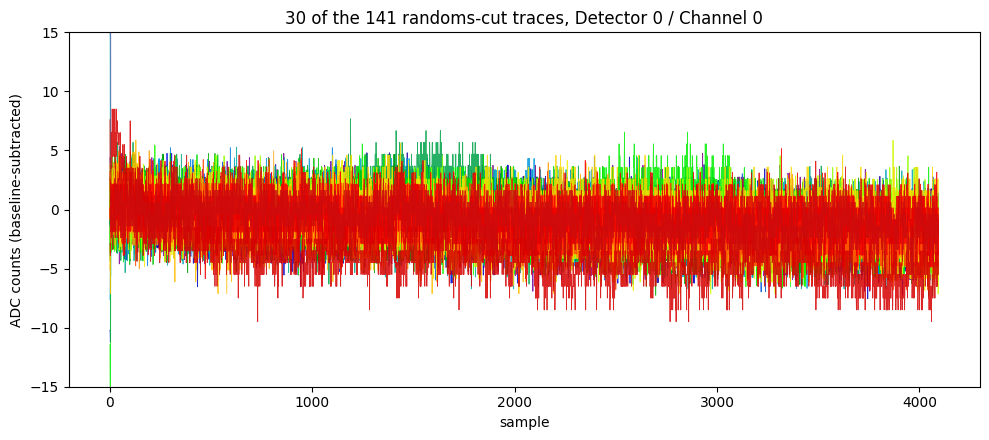

<Figure size 640x480 with 0 Axes>

In [4]:
bl = pq.bline(pulses, config_500)
rng = np.random.default_rng(0)
pick = rng.choice(np.flatnonzero(sel_randoms), size=min(30, sel_randoms.sum()), replace=False)
colors = plt.cm.nipy_spectral(np.linspace(0.05, 0.95, len(pick)))

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, c in zip(pick, colors):
    ax.plot(pulses[i] - bl[i], linewidth=0.6, color=c, alpha=0.85)
ax.set_ylim(-15, 15)    # the leading glitch (up to hundreds of counts) runs off the plot
ax.set_xlabel("sample")
ax.set_ylabel("ADC counts (baseline-subtracted)")
ax.set_title(f"{len(pick)} of the {sel_randoms.sum()} randoms-cut traces, Detector {DETECTOR} / Channel {CHANNEL}")
fig.tight_layout()
plt.show()
plt.savefig(f'figures/chan0-traces-07221203_2025_F0001.png')

## 4. Power spectrum

Each trace is baseline-subtracted and its first 10 samples are trimmed before the FFT (the glitch would otherwise leak broadband power into the low bins). Two normalizations are shown:

- **raw** `|FFT|^2`, which is what Note 3 plotted, so the two can be compared directly;
- a **one-sided PSD in counts^2/Hz**, `2 * dt * |FFT|^2 / N`, with `dt` the sample period and `N` the number of samples (the DC bin is dropped). This is one common convention; check it against the thesis convention cited in Note 3 before using it for optimal filtering.

The shaded band is the 16th to 84th percentile of the individual traces at each frequency.

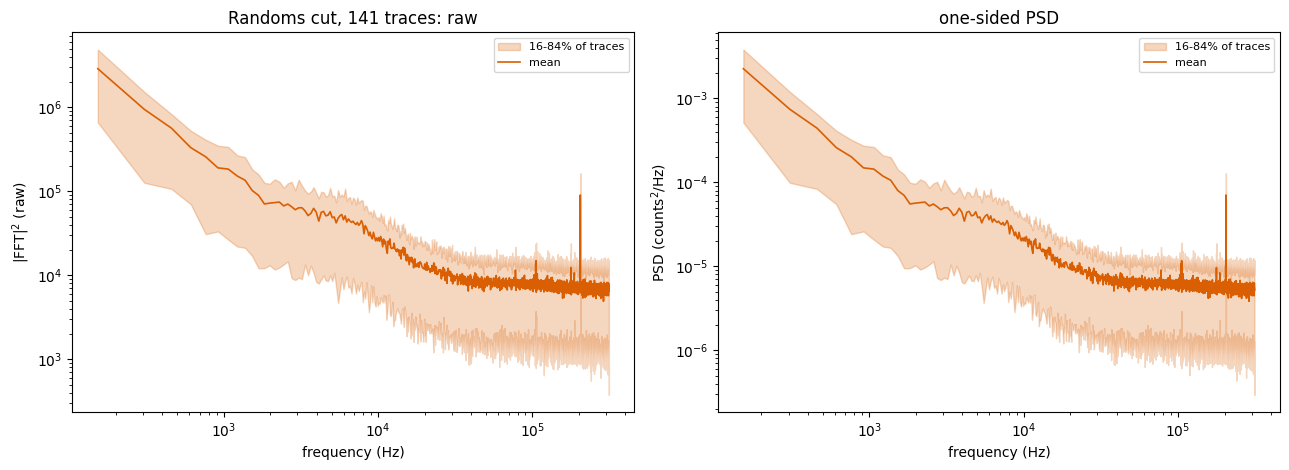

In [5]:
def processed(pulse_array):
    # baseline-subtract (500-sample window) and drop the leading glitch samples
    return po.trim_glitch(po.baseline_subtract(pulse_array, config_500), config_500)

flat = processed(pulses[sel_randoms])
n = flat.shape[-1]
freqs = pq.frequencies_hz(n, config_500)
raw = pq.power_spectrum(flat, config_500)                         # |FFT|^2, shape (traces, bins)
psd = raw * (2 * config_500.sample_period_s / n)                  # one-sided, counts^2/Hz

fig, (ax_raw, ax_psd) = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, arr, label in ((ax_raw, raw, r"$|\mathrm{FFT}|^2$ (raw)"), (ax_psd, psd, "PSD (counts$^2$/Hz)")):
    lo, mid, hi = np.percentile(arr, [16, 50, 84], axis=0)
    ax.fill_between(freqs[1:], lo[1:], hi[1:], color="#d95f02", alpha=0.25, label="16-84% of traces")
    ax.loglog(freqs[1:], arr.mean(axis=0)[1:], color="#d95f02", linewidth=1.2, label="mean")
    ax.set_xlabel("frequency (Hz)")
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
ax_raw.set_title(f"Randoms cut, {flat.shape[0]} traces: raw")
ax_psd.set_title("one-sided PSD")
fig.tight_layout()
plt.show()

## 5. Compared with Note 3

Note 3 used the 21-trace `good_noise_traces.csv` selection. Restricted to Detector 0 / Channel 0 it is 12 traces (the other 2 channel-0 traces are from Detector 1). To compare the *selections* and nothing else, both sets go through exactly the same processing as above.

Note 3 selection, Detector 0 / Channel 0: 12 traces; bstd (500 samples, glitch skipped) median 1.52 counts


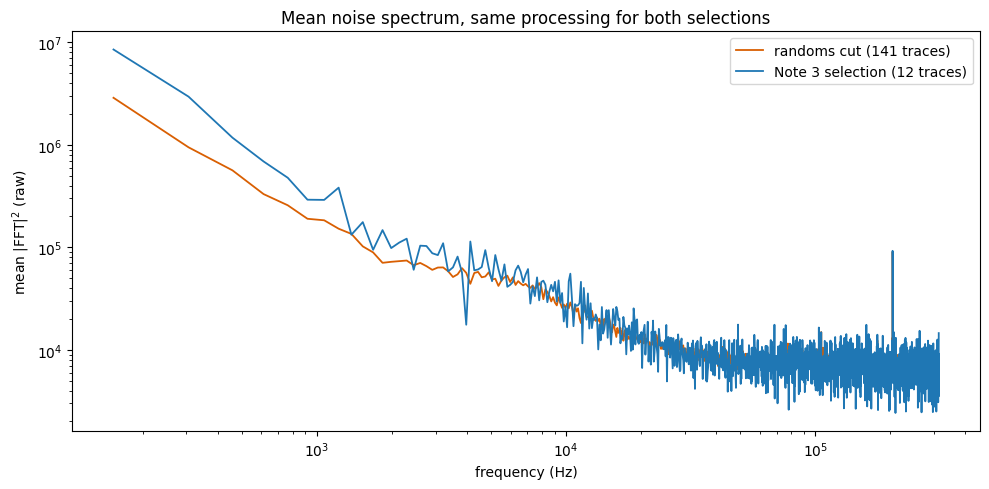

band (Hz)            randoms cut   Note 3 sel.   ratio
    1000-3000          9.35e+04      1.47e+05    0.64
    3000-10000         4.41e+04      5.24e+04    0.84
   10000-50000         1.16e+04      1.21e+04    0.96
   50000-150000        7.83e+03      7.55e+03    1.04
  250000-310000         6.8e+03      6.94e+03    0.98


In [6]:
rows = [r for r in csv.DictReader(open(REPO / "data_analysis" / "R76" / "notebooks" / "good_noise_traces.csv"))
        if int(r["channel"]) == CHANNEL and int(r["group"]) == DETECTOR]
old_ids = [f"{r['event']}_{r['group']}_Phonon_4096" for r in rows]
_, old_pulses = pio.load_channel_batch(cdms, old_ids, CHANNEL)
old_raw = pq.power_spectrum(processed(old_pulses), config_500)
print(f"Note 3 selection, Detector {DETECTOR} / Channel {CHANNEL}: {len(old_ids)} traces; "
      f"bstd (500 samples, glitch skipped) median {np.median(pq.bstd(old_pulses, config_500)):.2f} counts")

fig, ax = plt.subplots(figsize=(10, 5))
ax.loglog(freqs[1:], raw.mean(axis=0)[1:], color="#d95f02", linewidth=1.3, label=f"randoms cut ({raw.shape[0]} traces)")
ax.loglog(freqs[1:], old_raw.mean(axis=0)[1:], color="#1f77b4", linewidth=1.3, label=f"Note 3 selection ({old_raw.shape[0]} traces)")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel(r"mean $|\mathrm{FFT}|^2$ (raw)")
ax.legend()
ax.set_title("Mean noise spectrum, same processing for both selections")
fig.tight_layout()
plt.show()

bands = [(1e3, 3e3), (3e3, 1e4), (1e4, 5e4), (5e4, 1.5e5), (2.5e5, 3.1e5)]
print(f"{'band (Hz)':<18}{'randoms cut':>14}{'Note 3 sel.':>14}{'ratio':>8}")
for lo, hi in bands:
    m = (freqs >= lo) & (freqs < hi)
    a, b = raw.mean(axis=0)[m].mean(), old_raw.mean(axis=0)[m].mean()
    print(f"{lo:>8.0f}-{hi:<8.0f}{a:>14.3g}{b:>14.3g}{a / b:>8.2f}")

## Next steps

- Describe what differs between the two spectra, and decide whether the sharp peaks of Note 7 (which Note 7 traced to two Detector 1 traces) are present here.
- Repeat for Channels 1 to 3, and for Detector 1.
- Add the other dumps of the series (F0002 to F0005) with `pio.load_channel_batch_multi`, and check that the trigger-label assumption holds there.
- When this becomes a note: it supersedes Note 3, so the Note 3 row gets the Superseded status and a link to the new note.